# Analisis akurasi regional — GSM8K

Penyelarasan 6 Oktober 2026 mengikuti gender/religion. Seluruh angka dari tabel beku; tidak mengubah scoring atau Bab VI.

## 1. SPEC dan DESIGN PLAN

Seluruh 1.319 soal test, enam model, 16 skenario regional. N berasal dari eksperimen gender dan berbeda protokol; perbandingan terhadap N adalah sensitivitas, bukan klaim primer. Rencana: `docs/PENYELARASAN_AKURASI_REGIONAL_GENDER_RELIGION_2026-10-06.md`. Render PNG baru, verifikasi, arsipkan versi sebelumnya, pasang.

In [1]:
BENCHMARK="GSM8K"
FOLDER="akurasi analysis"
NOTEBOOK_NAME="GSM8K_Regional_Cultural_Accuracy_Analysis_Lengkap.ipynb"
from pathlib import Path
from datetime import datetime
import ast, hashlib, json, re, shutil, sys
import numpy as np
import pandas as pd
import matplotlib
matplotlib.use('Agg')
import matplotlib.pyplot as plt
import seaborn as sns
from matplotlib.text import Text
from matplotlib.collections import PathCollection
from PIL import Image as PILImage
from IPython.display import Image, Markdown, display
ROOT = next(p for p in (Path.cwd().resolve(), *Path.cwd().resolve().parents) if (p/'AGENTS.md').is_file())
sys.path.insert(0,str(ROOT))
sys.path.insert(0,str(ROOT/'src/pipelines/analysis'))
ACTIVE = ROOT/'notebooks/regional'/FOLDER
TABLE_DIR = (ROOT/'result/benchmarks/gsm8k/reports/persona_publication_analysis_v5_paired_significance_six_models_bar3_compact_smalllabels_heatmap3_sigbold/tables') if BENCHMARK=='GSM8K' else ACTIVE/'tables'
RUN_ID = datetime.now().strftime('%Y%m%d_%H%M%S_%f')
RUN = ROOT/'result/analyses/accuracy/runs'/('regional_'+BENCHMARK.lower()+'_presentation_'+RUN_ID)
FIGURE_DIR = RUN/'figures'
FIGURE_DIR.mkdir(parents=True,exist_ok=False)
def file_hash(path):
    return hashlib.sha256(Path(path).read_bytes()).hexdigest()
TABLE_HASHES = {str(p.resolve()):file_hash(p) for p in TABLE_DIR.glob('*.csv')}
LEGACY_STEMS = {'01_ethics_regional_absolute_accuracy_nine_categories','02_ethics_regional_delta_vs_neutral','03_ethics_regional_delta_implicit_vs_explicit','06_ethics_regional_effect_holm_heatmap','07_ethics_regional_exact_mcnemar_and_holm_pvalue_heatmap_part1','07_ethics_regional_exact_mcnemar_and_holm_pvalue_heatmap_part2','08_ethics_regional_combined_effect_holm_heatmap','09_ethics_regional_combined_exact_mcnemar_and_holm_pvalue_heatmap_part1','09_ethics_regional_combined_exact_mcnemar_and_holm_pvalue_heatmap_part2'}
MODEL_SOURCE = ['Qwen3 Next 80B-A3B','Llama 3.1 8B','Ministral 8B','DeepSeek R1-Distill 32B','GPT-OSS 20B','Llama 3.3 70B']
IDENTITIES = ['north_american','east_asian','south_asian','sub_saharan_african']
IL = dict(zip(IDENTITIES,['Amerika Utara','Asia Timur','Asia Selatan','Afrika Sub-Sahara']))
EN = dict(zip(IDENTITIES,['North American','East Asian','South Asian','Sub-Saharan African']))
PERSONAS = [i+'_'+c for i in IDENTITIES for c in ['explicit','implicit_1','implicit_2','implicit_3']]+['neutral']
PERSONA_LABELS = [IL[i]+' '+c for i in IDENTITIES for c in ['E','I1','I2','I3']]+['Neutral']
CATEGORIES = [IL[i]+' '+c for i in IDENTITIES for c in ['Explicit','Implicit Avg']]+['Neutral']
COLORS = ['#0047AB','#0086A8','#B80F2E','#E45700','#007A4D','#66A61E','#5B21B6','#A0006D','#30343B']
BACKGROUND = '#FCFBF8'
FONT_SIZES = dict(title=30,panel=26,axis=22,colorbar=25,cell=26)
RENDER_AUDIT = []
def display_label(value):
    s=str(value).replace('80B-A3B','80B')
    for old,new in [('DeepSeek R1-Distill','DeepSeek R1'),('Qwen3 Next 80B-A3B','Qwen3 Next 80B'),('North American','Amerika Utara'),('East Asian','Asia Timur'),('South Asian','Asia Selatan'),('Sub-Saharan African','Afrika Sub-Sahara'),('Regional Persona & Baseline','Persona regional dan skenario netral'),('Regional Cultural','Regional-Kultural'),('Global Neutral Avg','Rerata N enam model'),('Neutral Avg','Rerata N'),('Implicit Avg','Rerata I1–I3'),('Explicit','E'),('Implicit','I'),('Neutral','N'),('Accuracy','Akurasi'),('Difference on accuracy scale','Delta akurasi (skala 0–1)')]:
        s=s.replace(old,new)
    return s
def plot_values(fig):
    values=[]
    for ax in fig.axes:
        values += [np.array(line.get_xydata(),copy=True) for line in ax.lines]
        values += [np.array([p.get_x(),p.get_y(),p.get_width(),p.get_height()]) for p in ax.patches if hasattr(p,'get_height')]
        values += [np.array(c.get_array(),copy=True) for c in ax.collections if c.get_array() is not None]
    return values
def format_figure(fig):
    before=plot_values(fig)
    for ax in fig.axes:
        xlim,ylim=ax.get_xlim(),ax.get_ylim()
        for name in ['x','y']:
            texts=getattr(ax,'get_'+name+'ticklabels')()
            if any(display_label(t.get_text())!=t.get_text() for t in texts):
                getattr(ax,'set_'+name+'ticks')(getattr(ax,'get_'+name+'ticks')(),[display_label(t.get_text()) for t in texts])
        ax.set_xlim(xlim);ax.set_ylim(ylim)
        ax.title.set_fontweight('bold')
        for p in ax.patches:
            if hasattr(p,'get_height'): p.set_alpha(1)
        for c in ax.collections:
            if isinstance(c,PathCollection): c.set_alpha(1)
    for ax in fig.axes:
        for collection in ax.collections:
            a=collection.get_array()
            if a is not None and np.ndim(a)==2:
                for y,x in np.argwhere(np.ma.getmaskarray(a)):
                    ax.text(x+.5,y+.5,'NA',ha='center',va='center',fontsize=12,color='#17212B')
    for t in fig.findobj(Text): t.set_text(display_label(t.get_text()))
    if fig._suptitle: fig._suptitle.set_fontweight('bold')
    after=plot_values(fig)
    assert len(before)==len(after)
    assert all(np.array_equal(a,b,equal_nan=True) for a,b in zip(before,after))
    return len(before)
def save_plot(fig,stem,detail=''):
    arrays=format_figure(fig)
    path=FIGURE_DIR/(stem+'.png')
    assert not path.exists(),path
    fig.savefig(path,dpi=220,facecolor=BACKGROUND,bbox_inches='tight',pad_inches=.25)
    plt.close(fig)
    RENDER_AUDIT.append(dict(file=path.name,numeric_arrays_unchanged=arrays,detail=detail))
    print('PNG:',path.name,flush=True)
    return path
def show_figure(name,width=1300):
    if not name.endswith('.png'): name+='.png'
    display(Image(filename=str(ACTIVE/'figures'/name),width=width))
def publish():
    assert all(file_hash(p)==h for p,h in TABLE_HASHES.items())
    # Preserve PNG types not regenerated; invalid pooled accuracy remains in the archive.
    for p in (ACTIVE/'figures').glob('*.png'):
        if p.stem not in LEGACY_STEMS and not (FIGURE_DIR/p.name).exists():
            shutil.copy2(p,FIGURE_DIR/p.name)
    assert not list(FIGURE_DIR.glob('*.svg'))
    for p in FIGURE_DIR.glob('*.png'):
        with PILImage.open(p) as im: im.verify()
    archive=ACTIVE/'_arsip'/('accuracy_before_'+RUN_ID)
    archive.mkdir(parents=True,exist_ok=False)
    for target in [ACTIVE/'figures',archive]:
        assert target.resolve().is_relative_to((ROOT/'notebooks/regional').resolve())
    old={str(p.relative_to(ACTIVE/'figures')):file_hash(p) for p in (ACTIVE/'figures').rglob('*') if p.is_file()}
    shutil.move(str(ACTIVE/'figures'),str(archive/'figures'))
    assert old=={str(p.relative_to(archive/'figures')):file_hash(p) for p in (archive/'figures').rglob('*') if p.is_file()}
    for name in ['README.md','LATEST_RUN.json','output_index.csv','active_figures.csv','presentation_manifest.json','bundle_manifest.json']:
        if (ACTIVE/name).exists(): shutil.copy2(ACTIVE/name,archive/name)
    shutil.copy2(ACTIVE/NOTEBOOK_NAME,archive/NOTEBOOK_NAME)
    shutil.copytree(FIGURE_DIR,ACTIVE/'figures')
    index=pd.DataFrame([dict(kind='figure',file=p.name,relative_path='figures/'+p.name,path=str(ACTIVE/'figures'/p.name),sha256=file_hash(p),status='regenerated' if p.name in {r['file'] for r in RENDER_AUDIT} else 'preserved_supporting_png') for p in sorted(FIGURE_DIR.glob('*.png'))])
    index.to_csv(RUN/'figure_index.csv',index=False)
    index.to_csv(ACTIVE/'output_index.csv',index=False)
    index.rename(columns={'relative_path':'figure'}).to_csv(ACTIVE/'active_figures.csv',index=False)
    manifest=dict(benchmark=BENCHMARK,run=str(RUN),archive=str(archive),source_table_hashes=TABLE_HASHES,rendered=RENDER_AUDIT,png=len(index),svg=0,new_tests=False,rescoring=False,api_calls=0,latex_changed=False,legacy_accuracy_figures_archived=sorted(LEGACY_STEMS) if BENCHMARK=='ETHICS' else [])
    (RUN/'presentation_manifest.json').write_text(json.dumps(manifest,ensure_ascii=False,indent=2),encoding='utf-8')
    (ACTIVE/'presentation_manifest.json').write_text(json.dumps(manifest,ensure_ascii=False,indent=2),encoding='utf-8')
    (ACTIVE/'LATEST_RUN.json').write_text(json.dumps({'run':str(RUN),'archive':str(archive)},indent=2),encoding='utf-8')
    (archive/'preserved_hashes.json').write_text(json.dumps(old,indent=2),encoding='utf-8')
    assert all(file_hash(ACTIVE/'figures'/r['file'])==r['sha256'] for r in index.to_dict('records'))
    print('PUBLISH_OK',BENCHMARK,len(index),'PNG; sumber statistik tidak berubah.',flush=True)
    return manifest
sns.set_theme(style='whitegrid',font='DejaVu Sans')
plt.rcParams.update({'figure.facecolor':BACKGROUND,'axes.facecolor':BACKGROUND,'axes.titleweight':'bold','font.size':14,'axes.titlesize':23,'axes.labelsize':18,'xtick.labelsize':14,'ytick.labelsize':14,'legend.fontsize':13})

EXPECTED_TABLE_HASHES = {
  "accuracy_by_persona_six_models.csv": "692fbdb0502922c2d39a1e3c538e83126d749e9619b891920de9d64e2c44c1bb",
  "cochran_q_omnibus_all_groups.csv": "b78eebbf2e51dfef4770f0ddd6d0be947d8fae3f072af1ff12062fc1350182a5",
  "data_inventory_six_models.csv": "27a9e582690ca4904985261d2f14a46175a0c3904b95166cbef1ad7b7068633f",
  "explicit_implicit_descriptive_six_models.csv": "df84efe17f436ed0990a54f4c11b7439ca6ec00a758c2767c278043a8fd35b65",
  "gender_completion_token_accuracy_spearman_exploratory.csv": "a1559b3bf2c9a737fddbb51f04897530bdbaebed0c0f345edd961cd1a59eb055",
  "gender_completion_token_accuracy_tradeoff_implicit_vs_explicit.csv": "770f3078375fe8a79481e79373bca7c3aca7e010c1beda5044b277ba305ad9fa",
  "gender_completion_token_delta_vs_neutral_pct.csv": "1fde4e6841891381da4f741abbb875c79237449564575bead231306c8e2b7de5",
  "gender_delta_component_significance_markers.csv": "de5218ba9f5d79d74de7ffc1b833a435460d7d74b4e592716a4f93dd2ec605a1",
  "gender_five_category_and_deltas.csv": "926c8e6adddfa1005cf2f064e32a92b1f3578d0ae097f877aeda073e9818f6eb",
  "gender_paired_effects_significance.csv": "986ee584fbd092e28b3ff31b57e53dfc432c16b4edb037167e340757b5740532",
  "legacy_aggregate_comparison.csv": "a644ebe5f006b381f7dedc799f6b9185d49a0042403316cfbd3ad8fca3c9ec99",
  "marginal_accuracy_effects_six_models.csv": "92b2b0ba5248312e101c8741b92e5f83e4c275b49122ff98503b5be3aac64e05",
  "model_token_efficiency_six_models.csv": "f5c1be06bfcfa083aaebcd723b7474811d71ed5420f8fec6fba8b25425a3f7e3",
  "neutral_persona_accuracy_six_models.csv": "bd10ef481280a6f46a26d1ce2845e875837a0513da36f87246722fac09bd57b8",
  "paired_effects_significance_all_groups.csv": "c43d000534bc83d38d9fa7d2f99768d61a3de15c964fe4f765c3173b68734f9b",
  "qwen_gender_accuracy_after_rerun_4096.csv": "31121316b8065e01adfb557d2ccb024c5c6d0d14fd16d4cf4b61e47ca3595dc4",
  "reasoning_token_metadata_availability.csv": "db6dd71b31fc76a92c7f62dc12db8d8a04ed3bf9520239ca0aecf1a0a18fc8ca",
  "regional_accuracy_and_deltas.csv": "020320ede59d6357b0a9e36c61f9722ff2df7ba887becd48a1b1931a12e934e8",
  "regional_all_52_paired_effects_significance.csv": "f6e777e3f49d5335f08532edb56e59dec3f35b318b1d01432a130ce956fe9c6a",
  "regional_average_delta_vs_neutral.csv": "1977192a60bfaae431410d75c55e4fbfd8c4de6e0d31e6bd1b34aa2f67545d6d",
  "regional_completion_token_delta_implicit_vs_explicit.csv": "2b16332b267044bcf7582cf7ff1d6b5cd3d38387e43131aaf275109287f5b890",
  "regional_paired_effects_significance.csv": "45135b29d095a300c1d86c886c4640f4b745d2856cd3c1ab200545b844c5c272",
  "regional_reasoning_token_delta_implicit_vs_explicit.csv": "cd44054aafabe7564f370d2d78d0fcc9fabc81212ca0db3ae784d4cb6241b8b3",
  "regional_token_category_summary.csv": "4fe1a1c9260bbc96ec5eeb00405ddc7a5c8f822abccafc28cba2b644872fee49",
  "religion_average_delta_vs_neutral.csv": "ece68becd65bb1d071931c68f95078525453d999d68ce309fd3c0e63b54b4ee1",
  "religion_completion_token_delta_implicit_vs_explicit_pct.csv": "021f192af81c23a76b7c1aa10e367fedb5121db493801e63336348aef0e37d7d",
  "religion_explicit_implicit_and_deltas.csv": "6b2859dd2e508dda0528c16282ece5fde341c98bea2fcf467b32334ec54233d9",
  "religion_identity_pair_effects.csv": "68e641a02822dc121223e82f70a421462ff008aca5a5256dc73ac1fa4335bef3",
  "religion_paired_effects_significance.csv": "2eb18cef8c4de60cb24127079fd21957152b34a0e4fad626c7ba7a0120bad791",
  "religion_reasoning_token_delta_implicit_vs_explicit_pct.csv": "cfe34fbe370731cd59233d67328ad39986d61a2fb20bff7fd3f4c0430972caae",
  "source_consistency_audit.csv": "844de2e1aa6ce8a4547c54565dc41e2f659113ef0ee5c76e93905f68520a4532",
  "source_manifest.csv": "59235aa5189f99ae24db3d6451e91838c2b1ba062af63799537da9df088c90dc",
  "token_category_summary_six_models.csv": "23c3f00dc5fb2d5fd2dcf6a7dc8def440250246e4ff3beb4da1a90d552a813e4",
  "token_descriptive_effects_six_models.csv": "af79e6e0cb7ea16224f2cd8680900ddd11b5dc2c48bbdd73ee032d314248443d"
}
assert all(file_hash(TABLE_DIR/name)==digest for name,digest in EXPECTED_TABLE_HASHES.items())


## 2. CHECKLIST — denominator, arah dan statistik sumber

In [2]:
accuracy_all=pd.read_csv(TABLE_DIR/'accuracy_by_persona_six_models.csv')
regional_accuracy=accuracy_all[accuracy_all.dataset.eq('Regional Cultural')].copy()
regional_summary=pd.read_csv(TABLE_DIR/'regional_accuracy_and_deltas.csv')
regional_pairs=pd.read_csv(TABLE_DIR/'regional_paired_effects_significance.csv')
regional_all=pd.read_csv(TABLE_DIR/'regional_all_52_paired_effects_significance.csv')
regional_omnibus=pd.read_csv(TABLE_DIR/'cochran_q_omnibus_all_groups.csv').query("dataset=='Regional Cultural'")
assert len(regional_accuracy)==96 and regional_accuracy.raw_total.eq(1319).all()
assert len(regional_summary)==6 and len(regional_pairs)==72 and len(regional_omnibus)==24
assert len(regional_all)==312 and regional_all.groupby('model').size().eq(52).all()
assert regional_all.family_size.value_counts().to_dict()=={24:144,4:96,3:72}
assert regional_all.analysis_scope.value_counts().to_dict()=={'exploratory':144,'sensitivity':96,'primary':72}
assert np.allclose(regional_all.risk_difference_pp,regional_all.accuracy_a_pct-regional_all.accuracy_b_pct)
h=2*np.arcsin(np.sqrt(regional_all.accuracy_a_pct/100))-2*np.arcsin(np.sqrt(regional_all.accuracy_b_pct/100))
assert np.allclose(h,regional_all.cohen_h)
assert regional_all.significant_holm_0_05.eq(regional_all.holm_adjusted_p_value.lt(.05)).all()
print('VALIDATION_OK: 96 baris akurasi; 312 kontras; Holm 3/4/24; arah A-B tetap.')


VALIDATION_OK: 96 baris akurasi; 312 kontras; Holm 3/4/24; arah A-B tetap.


## 3. Akurasi dan coverage

Tabel menyimpan denominator, committed, abstain dan missing. Akurasi dibaca bersama coverage. Rerata I1–I3 pada bar hanya deskriptif.

In [3]:
columns = ['model_label', 'persona', 'raw_total', 'correct', 'total', 'accuracy_pct',
           'committed', 'commit_rate_pct', 'abstain', 'missing', 'technical_failures',
           'accuracy_committed_pct']
display(regional_accuracy[columns].sort_values(['model_label', 'persona']).reset_index(drop=True).style.format({
    'accuracy_pct': '{:.4f}%', 'commit_rate_pct': '{:.4f}%',
    'accuracy_committed_pct': '{:.4f}%'}))

display(Markdown('### Ringkasan yang dipakai untuk Figure 12 dan 13'))
display(regional_summary.style.format(precision=4))

,model_label,persona,raw_total,correct,total,accuracy_pct,committed,commit_rate_pct,abstain,missing,technical_failures,accuracy_committed_pct
0,DeepSeek R1-Distill 32B,east_asian_explicit,1319,1248,1319,94.6171%,1319,100.0000%,0,0,0,94.6171%
1,DeepSeek R1-Distill 32B,east_asian_implicit_1,1319,1237,1319,93.7832%,1317,99.8484%,2,0,0,93.9256%
2,DeepSeek R1-Distill 32B,east_asian_implicit_2,1319,1238,1319,93.8590%,1312,99.4693%,7,0,0,94.3598%
3,DeepSeek R1-Distill 32B,east_asian_implicit_3,1319,1250,1319,94.7688%,1313,99.5451%,6,0,0,95.2018%
4,DeepSeek R1-Distill 32B,north_american_explicit,1319,1248,1319,94.6171%,1319,100.0000%,0,0,0,94.6171%
5,DeepSeek R1-Distill 32B,north_american_implicit_1,1319,1228,1319,93.1008%,1311,99.3935%,8,0,0,93.6690%
6,DeepSeek R1-Distill 32B,north_american_implicit_2,1319,1233,1319,93.4799%,1314,99.6209%,5,0,0,93.8356%
7,DeepSeek R1-Distill 32B,north_american_implicit_3,1319,1221,1319,92.5701%,1315,99.6967%,4,0,0,92.8517%
8,DeepSeek R1-Distill 32B,south_asian_explicit,1319,1253,1319,94.9962%,1319,100.0000%,0,0,0,94.9962%
9,DeepSeek R1-Distill 32B,south_asian_implicit_1,1319,1234,1319,93.5557%,1313,99.5451%,6,0,0,93.9832%


### Ringkasan yang dipakai untuk Figure 12 dan 13

,model,model_label,Neutral,North American Explicit,North American Implicit Avg,North American Delta Imp-Exp,East Asian Explicit,East Asian Implicit Avg,East Asian Delta Imp-Exp,South Asian Explicit,South Asian Implicit Avg,South Asian Delta Imp-Exp,Sub-Saharan African Explicit,Sub-Saharan African Implicit Avg,Sub-Saharan African Delta Imp-Exp
0,qwen_qwen3-next-80b-a3b-thinking,Qwen3 Next 80B-A3B,94.0819,96.5883,95.3753,-1.2130,95.9060,95.5752,-0.3308,96.4367,95.1226,-1.3141,96.5125,95.3489,-1.1636
1,meta-llama_llama-3.1-8b-instruct,Llama 3.1 8B,84.3063,82.6384,81.9308,-0.7076,83.2449,81.6022,-1.6427,83.6998,82.7394,-0.9603,82.6384,80.6672,-1.9712
2,mistralai_ministral-8b-2512,Ministral 8B,93.4750,91.9636,91.8625,-0.1011,91.0538,91.1044,0.0505,89.6892,90.6242,0.9351,91.3571,90.0430,-1.3141
3,deepseek_deepseek-r1-distill-qwen-32b,DeepSeek R1-Distill 32B,93.9300,94.6171,93.0503,-1.5668,94.6171,94.1370,-0.4802,94.9962,93.9601,-1.0361,94.5413,93.5305,-1.0109
4,openai_gpt-oss-20b,GPT-OSS 20B,93.9302,92.0213,91.5280,-0.4933,92.9385,92.4633,-0.4752,91.7933,91.8774,0.0841,92.1152,91.8857,-0.2296
5,meta-llama_llama-3.3-70b-instruct,Llama 3.3 70B,91.9575,92.2669,92.6207,0.3538,93.2525,92.4438,-0.8087,94.1622,92.8734,-1.2889,92.9492,92.5954,-0.3538


## 4. IMPLEMENTATION — render PNG dan pengarsipan

Nilai batang tetap; sumbu akurasi dimulai dari nol. Warna wilayah E/I sama dengan ETHICS regional. Bintang memakai Holm sumber; perbandingan terhadap N tetap sensitivitas.

PNG: 12_regional_absolute_accuracy_explicit_implicit.png


PNG: 13_regional_delta_implicit_vs_explicit.png


PNG: 27_regional_all_52_effect_holm_stacked_26_26.png


PUBLISH_OK GSM8K 3 PNG; sumber statistik tidak berubah.


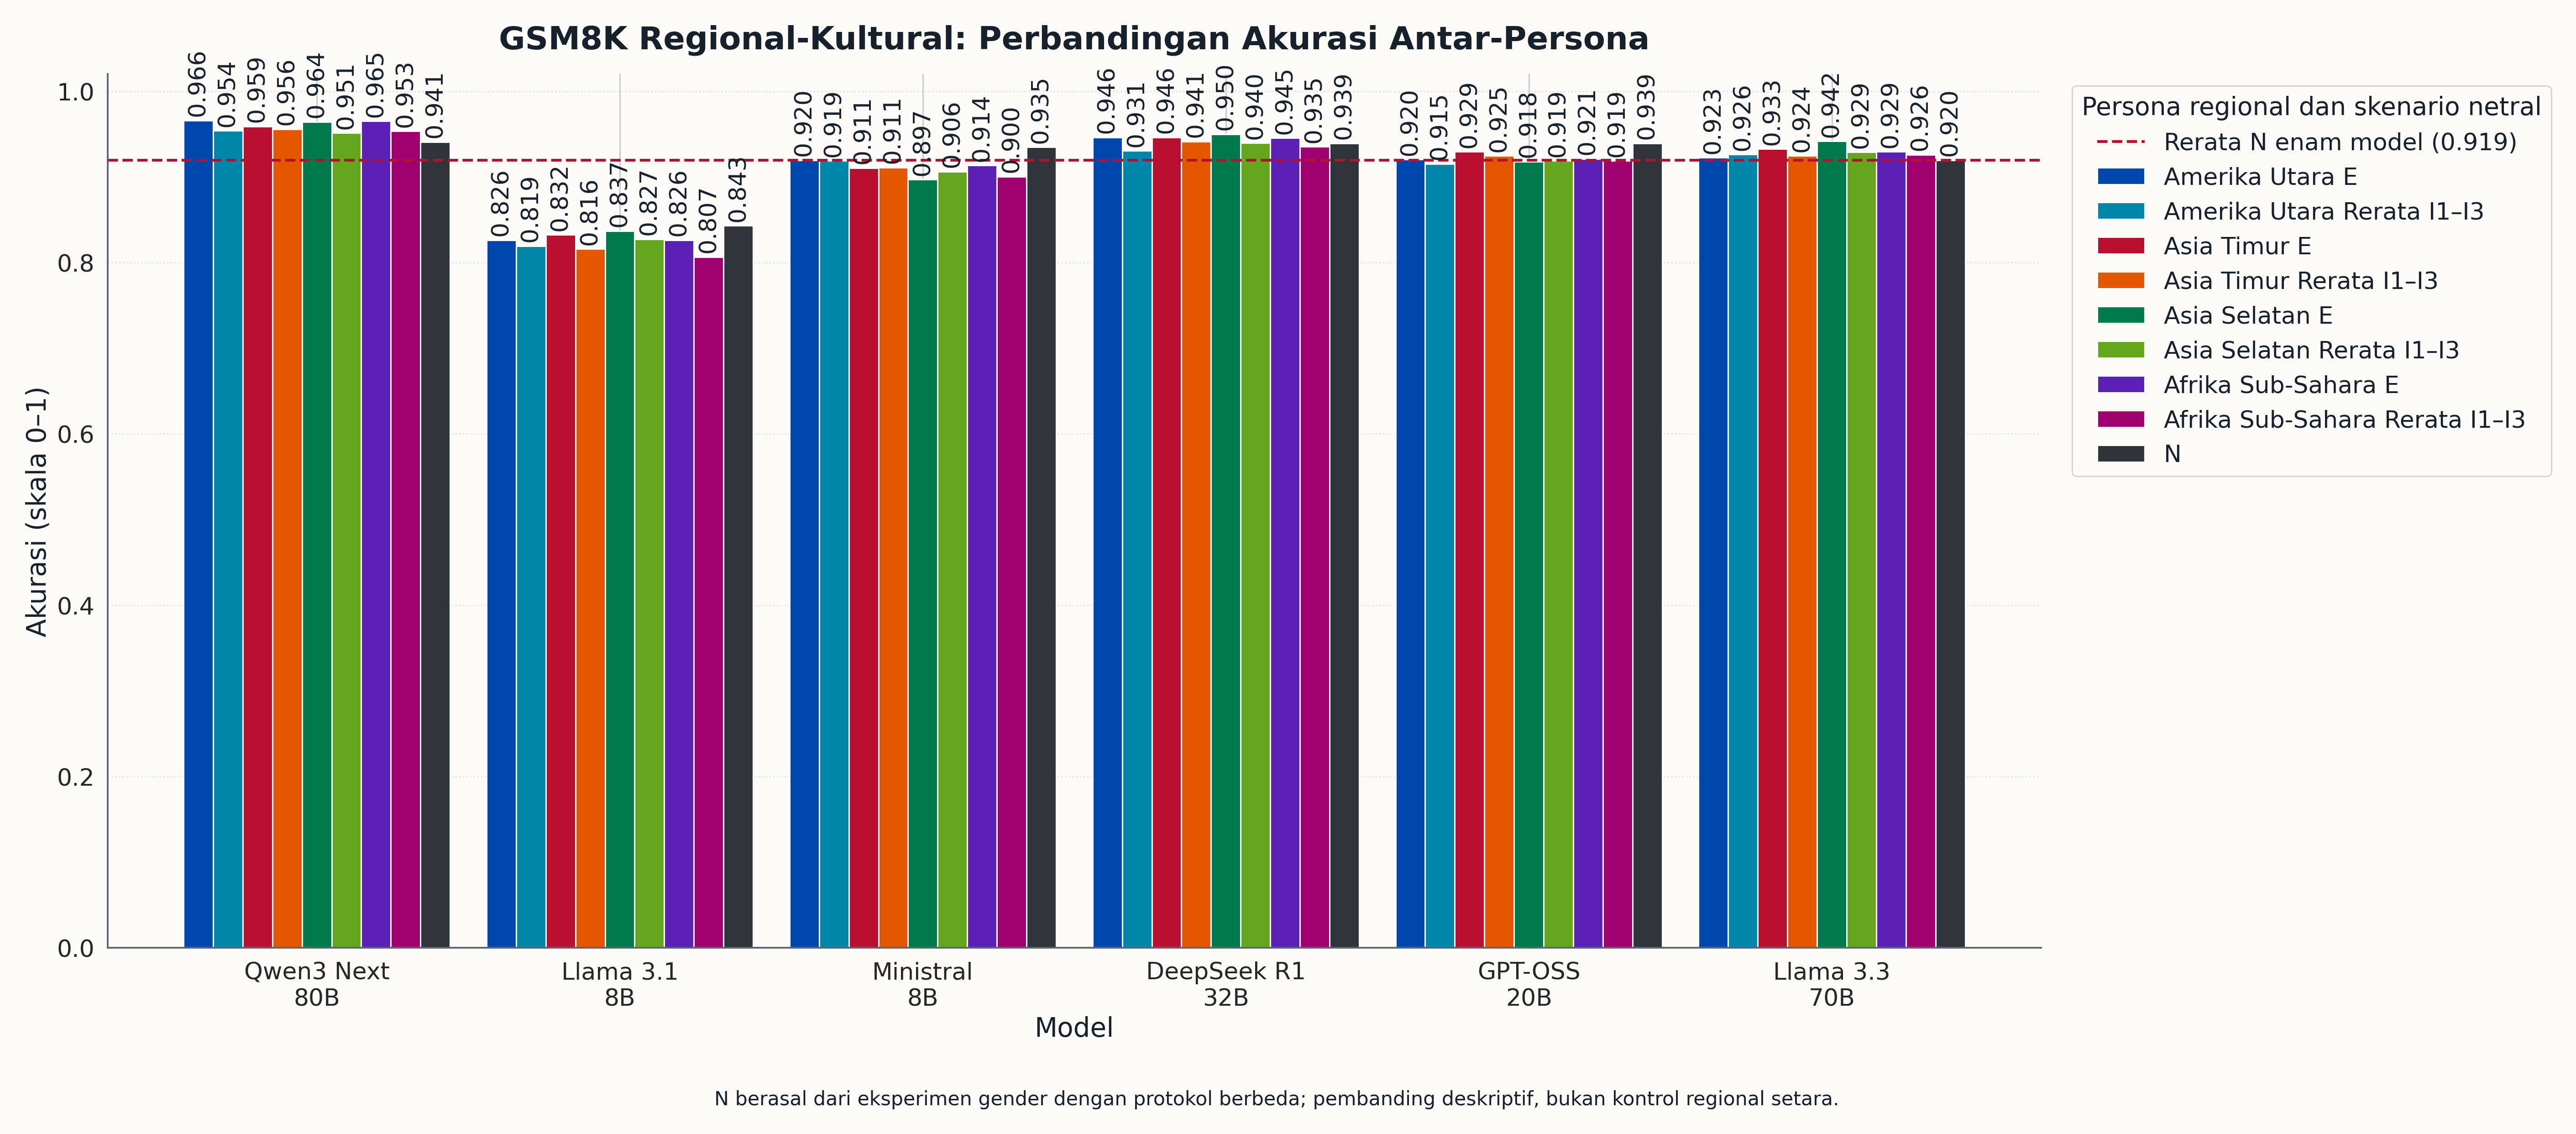

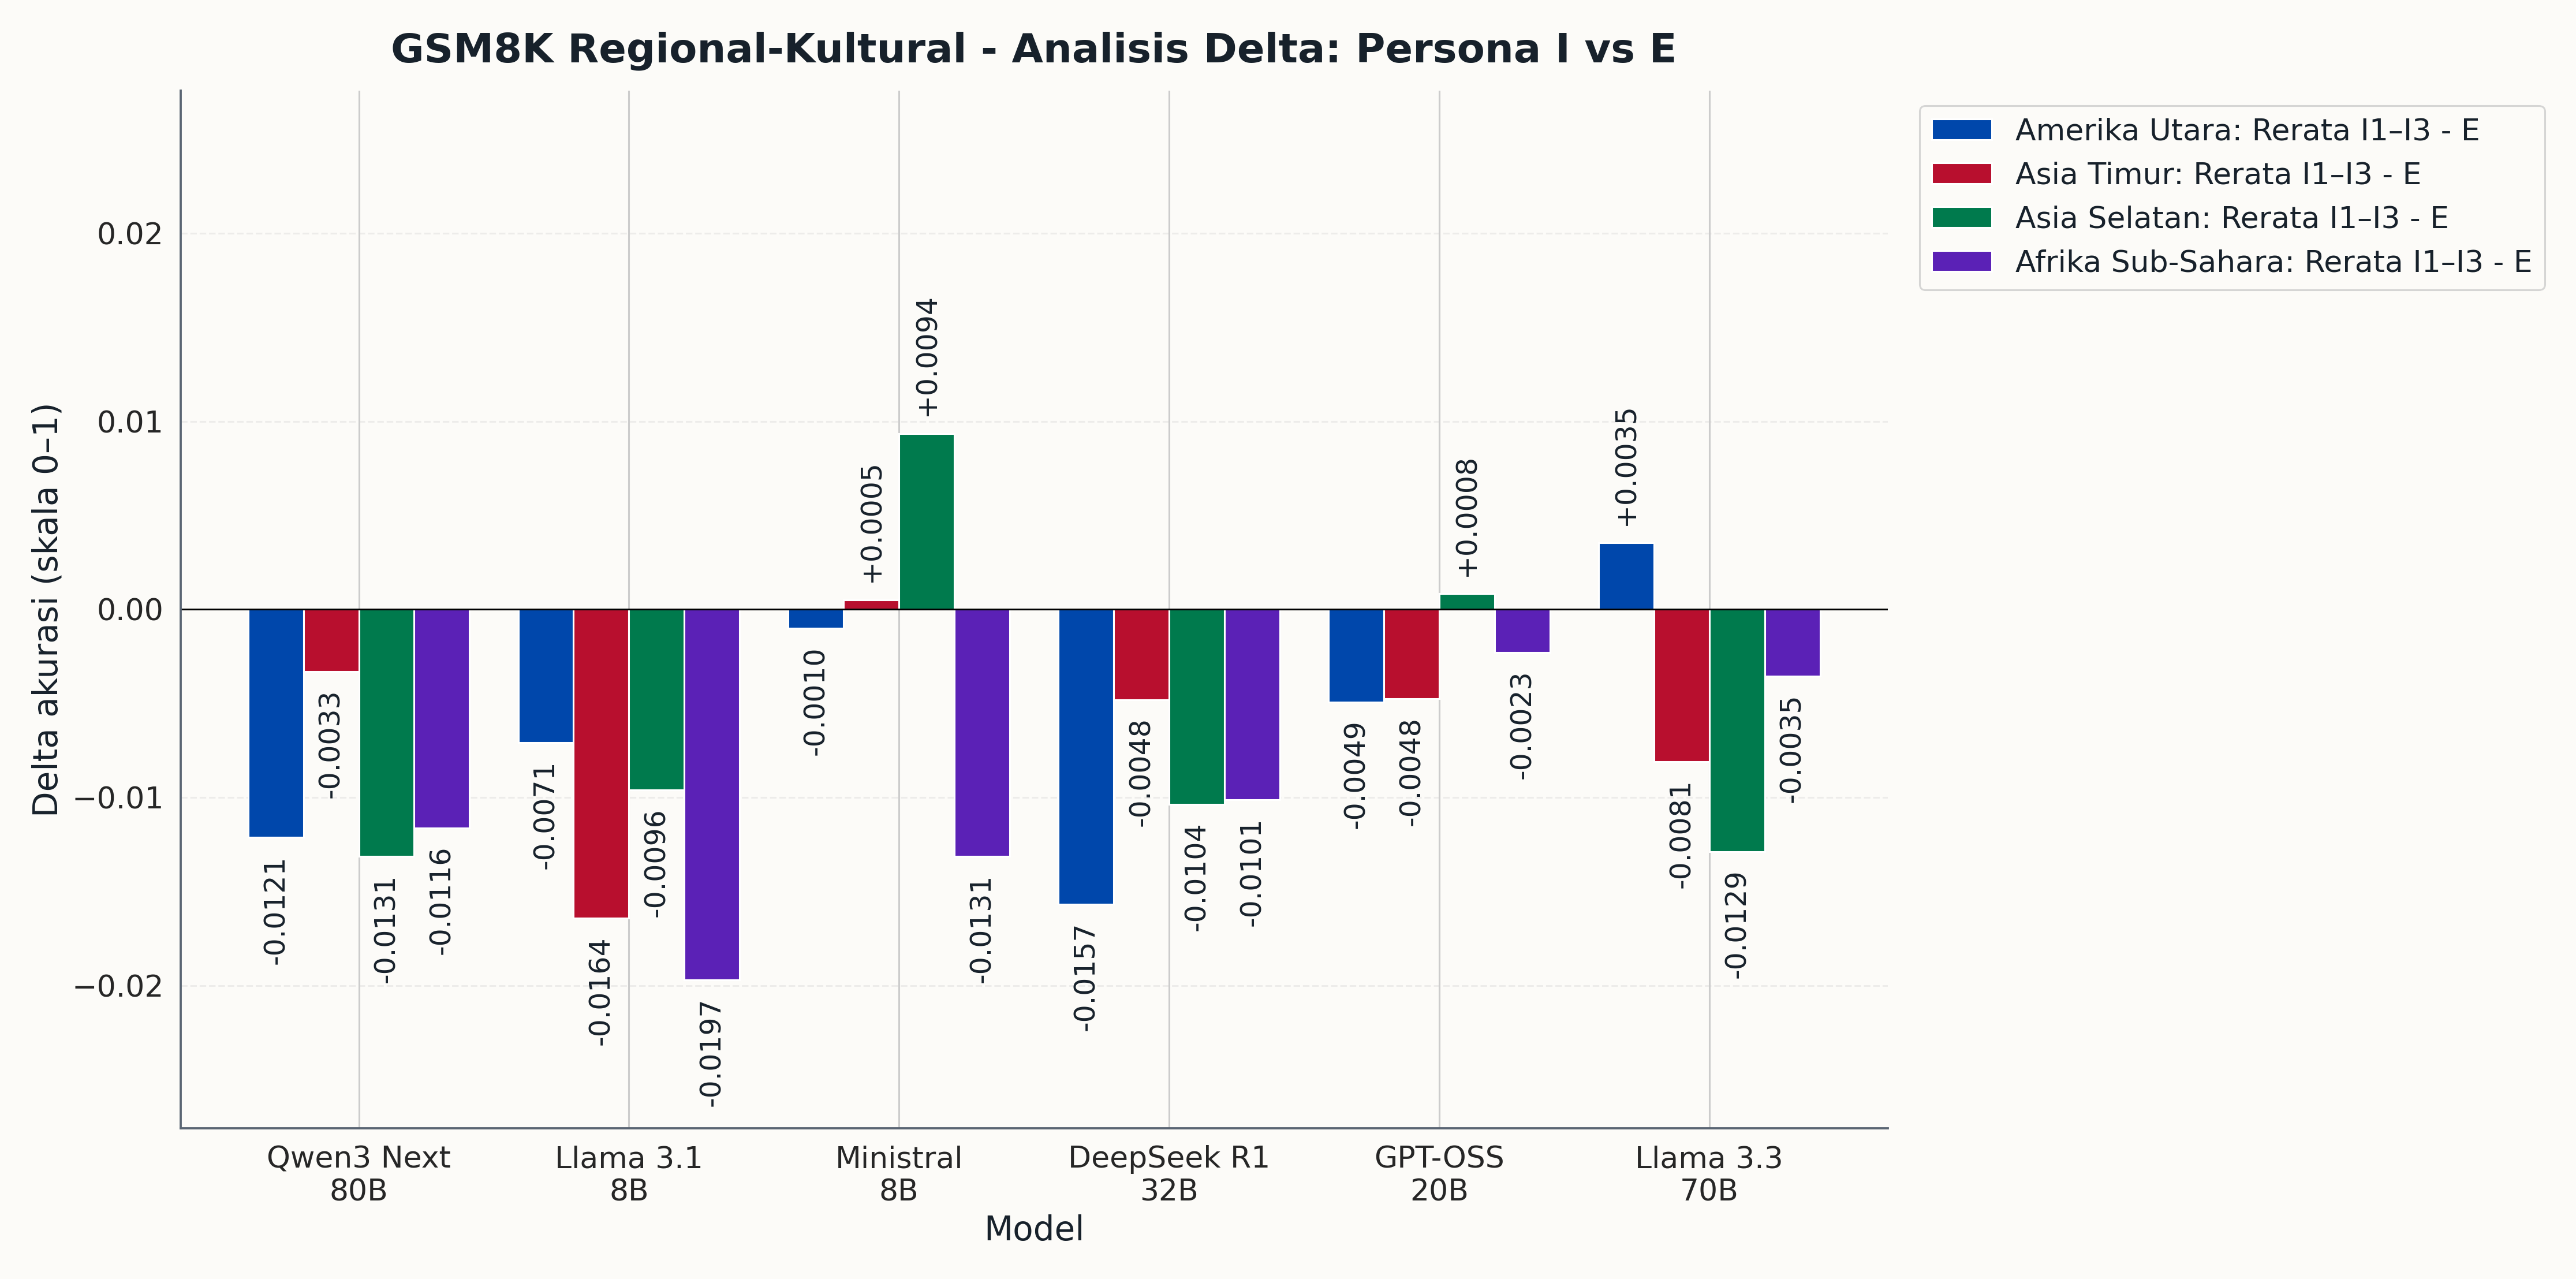

In [4]:
import render_gsm8k_regional_accuracy_standardized as renderer
renderer.ACCURACY_COLORS=list(COLORS)
renderer.DELTA_COLORS=list(COLORS[::2][:-1])
old_save=renderer._save_pair
def notebook_save(fig,directory,stem,dpi):
    if stem.startswith('12_'):
        fig.axes[0].set_ylim(0,1.02)
        fig.axes[0].set_ylabel('Akurasi (skala 0–1)')
        fig.text(.5,-.035,'N berasal dari eksperimen gender dengan protokol berbeda; pembanding deskriptif, bukan kontrol regional setara.',ha='center',fontsize=14)
    if stem.startswith('27_'):
        for ax in fig.axes[:4]:
            labels=[re.sub(r'\b(NA|EA|SA|SSA)\b',lambda m:{'NA':'AU','EA':'AT','SA':'AS','SSA':'ASS'}[m.group()],t.get_text()) for t in ax.get_xticklabels()]
            ax.set_xticks(ax.get_xticks(),labels)
        fig.text(.5,.006,'A−B = kiri−kanan · * p Holm <0,05 · AU: Amerika Utara; AT: Asia Timur; AS: Asia Selatan; ASS: Afrika Sub-Sahara\n'
                 'N: netral; E: eksplisit; I1–I3: implisit · † vs N: sensitivitas, protokol berbeda · ‡ antarkawasan: eksploratif',ha='center',fontsize=10)
    save_plot(fig,stem,'Tabel v5 beku; tanpa uji ulang')
renderer._save_pair=notebook_save
try:
    renderer._style()
    renderer.render_accuracy_and_delta(renderer._ordered(regional_summary),FIGURE_DIR,220)
    renderer.render_effect_heatmap(regional_all,FIGURE_DIR,220)
finally:
    renderer._save_pair=old_save
manifest=publish()
readme=f"""# Akurasi regional — GSM8K
Penyelarasan 6 Oktober 2026 langsung dalam notebook. PNG aktif: figures/. Run: {RUN}.
Arsip sebelumnya: {manifest['archive']}. SVG lama tidak dihapus permanen.
Amerika Utara/Asia Timur/Asia Selatan/Afrika Sub-Sahara dan warna E/I sama dengan ETHICS regional.
N berasal dari Gender Neutral dengan protokol berbeda; perbandingan terhadap N adalah sensitivitas.
Bar rerata I1–I3 deskriptif; uji I1/I2/I3 tetap terpisah. Sumbu akurasi mulai nol; nilai tidak berubah.
Arah A−B=kiri−kanan. * p Holm <0,05; family sumber 3/4/24. Bintang bukan otomatis klaim primer.
AU/AT/AS/ASS adalah singkatan wilayah di heatmap, bukan kode missing; NA yang berarti tidak tersedia tidak dipaksa nol.
† sensitivitas vs N; ‡ antarkawasan eksploratif. Dukungan pasangan dan gate omnibus pada tabel notebook.
Tabel v5: {TABLE_DIR}. Hash sumber dan PNG: presentation_manifest.json / output_index.csv.
Notebook membuat run baru setiap eksekusi. Tidak ada scoring, API, uji ulang, perubahan linguistic marker atau Bab VI.
"""
(ACTIVE/'README.md').write_text(readme,encoding='utf-8')
show_figure('12_regional_absolute_accuracy_explicit_implicit')
show_figure('13_regional_delta_implicit_vs_explicit')


## 5. Ukuran efek, Exact McNemar, Cochran’s Q dan Holm

52 kontras/model: 12 I–E primer, 16 persona–N sensitivitas, 24 antarkawasan eksploratif. Arah label dan koreksi tidak diubah.

,model_label,family,family_size,comparisons,holm_significant
0,DeepSeek R1-Distill 32B,east_asian_neutral_sensitivity_four,4,4,0
1,DeepSeek R1-Distill 32B,east_asian_primary_three,3,3,0
2,DeepSeek R1-Distill 32B,north_american_neutral_sensitivity_four,4,4,0
3,DeepSeek R1-Distill 32B,north_american_primary_three,3,3,1
4,DeepSeek R1-Distill 32B,regional_cross_identity_twenty_four,24,24,1
5,DeepSeek R1-Distill 32B,south_asian_neutral_sensitivity_four,4,4,0
6,DeepSeek R1-Distill 32B,south_asian_primary_three,3,3,0
7,DeepSeek R1-Distill 32B,sub_saharan_african_neutral_sensitivity_four,4,4,0
8,DeepSeek R1-Distill 32B,sub_saharan_african_primary_three,3,3,0
9,GPT-OSS 20B,east_asian_neutral_sensitivity_four,4,4,0


,model_label,identity,analysis_scope,family,family_size,comparison_label,n_pairs,accuracy_a_pct,accuracy_b_pct,risk_difference_pp,cohen_h,mcnemar_exact_p_value,holm_adjusted_p_value,significant_holm_0_05,decision_significant_0_05,supports_primary_claim
0,DeepSeek R1-Distill 32B,east_asian,primary,east_asian_primary_three,3,East Asian Implicit 1 - East Asian Explicit,1319,93.783169,94.617134,-0.833965,-0.035701,0.266412,0.799237,False,False,False
1,DeepSeek R1-Distill 32B,east_asian,primary,east_asian_primary_three,3,East Asian Implicit 2 - East Asian Explicit,1319,93.858984,94.617134,-0.758150,-0.032552,0.314307,0.799237,False,False,False
2,DeepSeek R1-Distill 32B,east_asian,primary,east_asian_primary_three,3,East Asian Implicit 3 - East Asian Explicit,1319,94.768764,94.617134,0.151630,0.006764,0.907561,0.907561,False,False,False
3,DeepSeek R1-Distill 32B,north_american,primary,north_american_primary_three,3,North American Implicit 1 - North American Exp...,1319,93.100834,94.617134,-1.516300,-0.063274,0.035241,0.070483,False,False,False
4,DeepSeek R1-Distill 32B,north_american,primary,north_american_primary_three,3,North American Implicit 2 - North American Exp...,1319,93.479909,94.617134,-1.137225,-0.048121,0.123853,0.123853,False,False,False
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
67,Qwen3 Next 80B-A3B,south_asian,primary,south_asian_primary_three,3,South Asian Implicit 2 - South Asian Explicit,1319,95.072024,96.436694,-1.364670,-0.067898,0.005098,0.010195,True,True,True
68,Qwen3 Next 80B-A3B,south_asian,primary,south_asian_primary_three,3,South Asian Implicit 3 - South Asian Explicit,1319,94.996209,96.436694,-1.440485,-0.071387,0.003378,0.010134,True,True,True
69,Qwen3 Next 80B-A3B,sub_saharan_african,primary,sub_saharan_african_primary_three,3,Sub-Saharan African Implicit 1 - Sub-Saharan A...,1319,95.754359,96.512509,-0.758150,-0.039370,0.121449,0.121449,False,False,False
70,Qwen3 Next 80B-A3B,sub_saharan_african,primary,sub_saharan_african_primary_three,3,Sub-Saharan African Implicit 2 - Sub-Saharan A...,1319,94.768764,96.512509,-1.743745,-0.085821,0.000191,0.000573,True,True,True


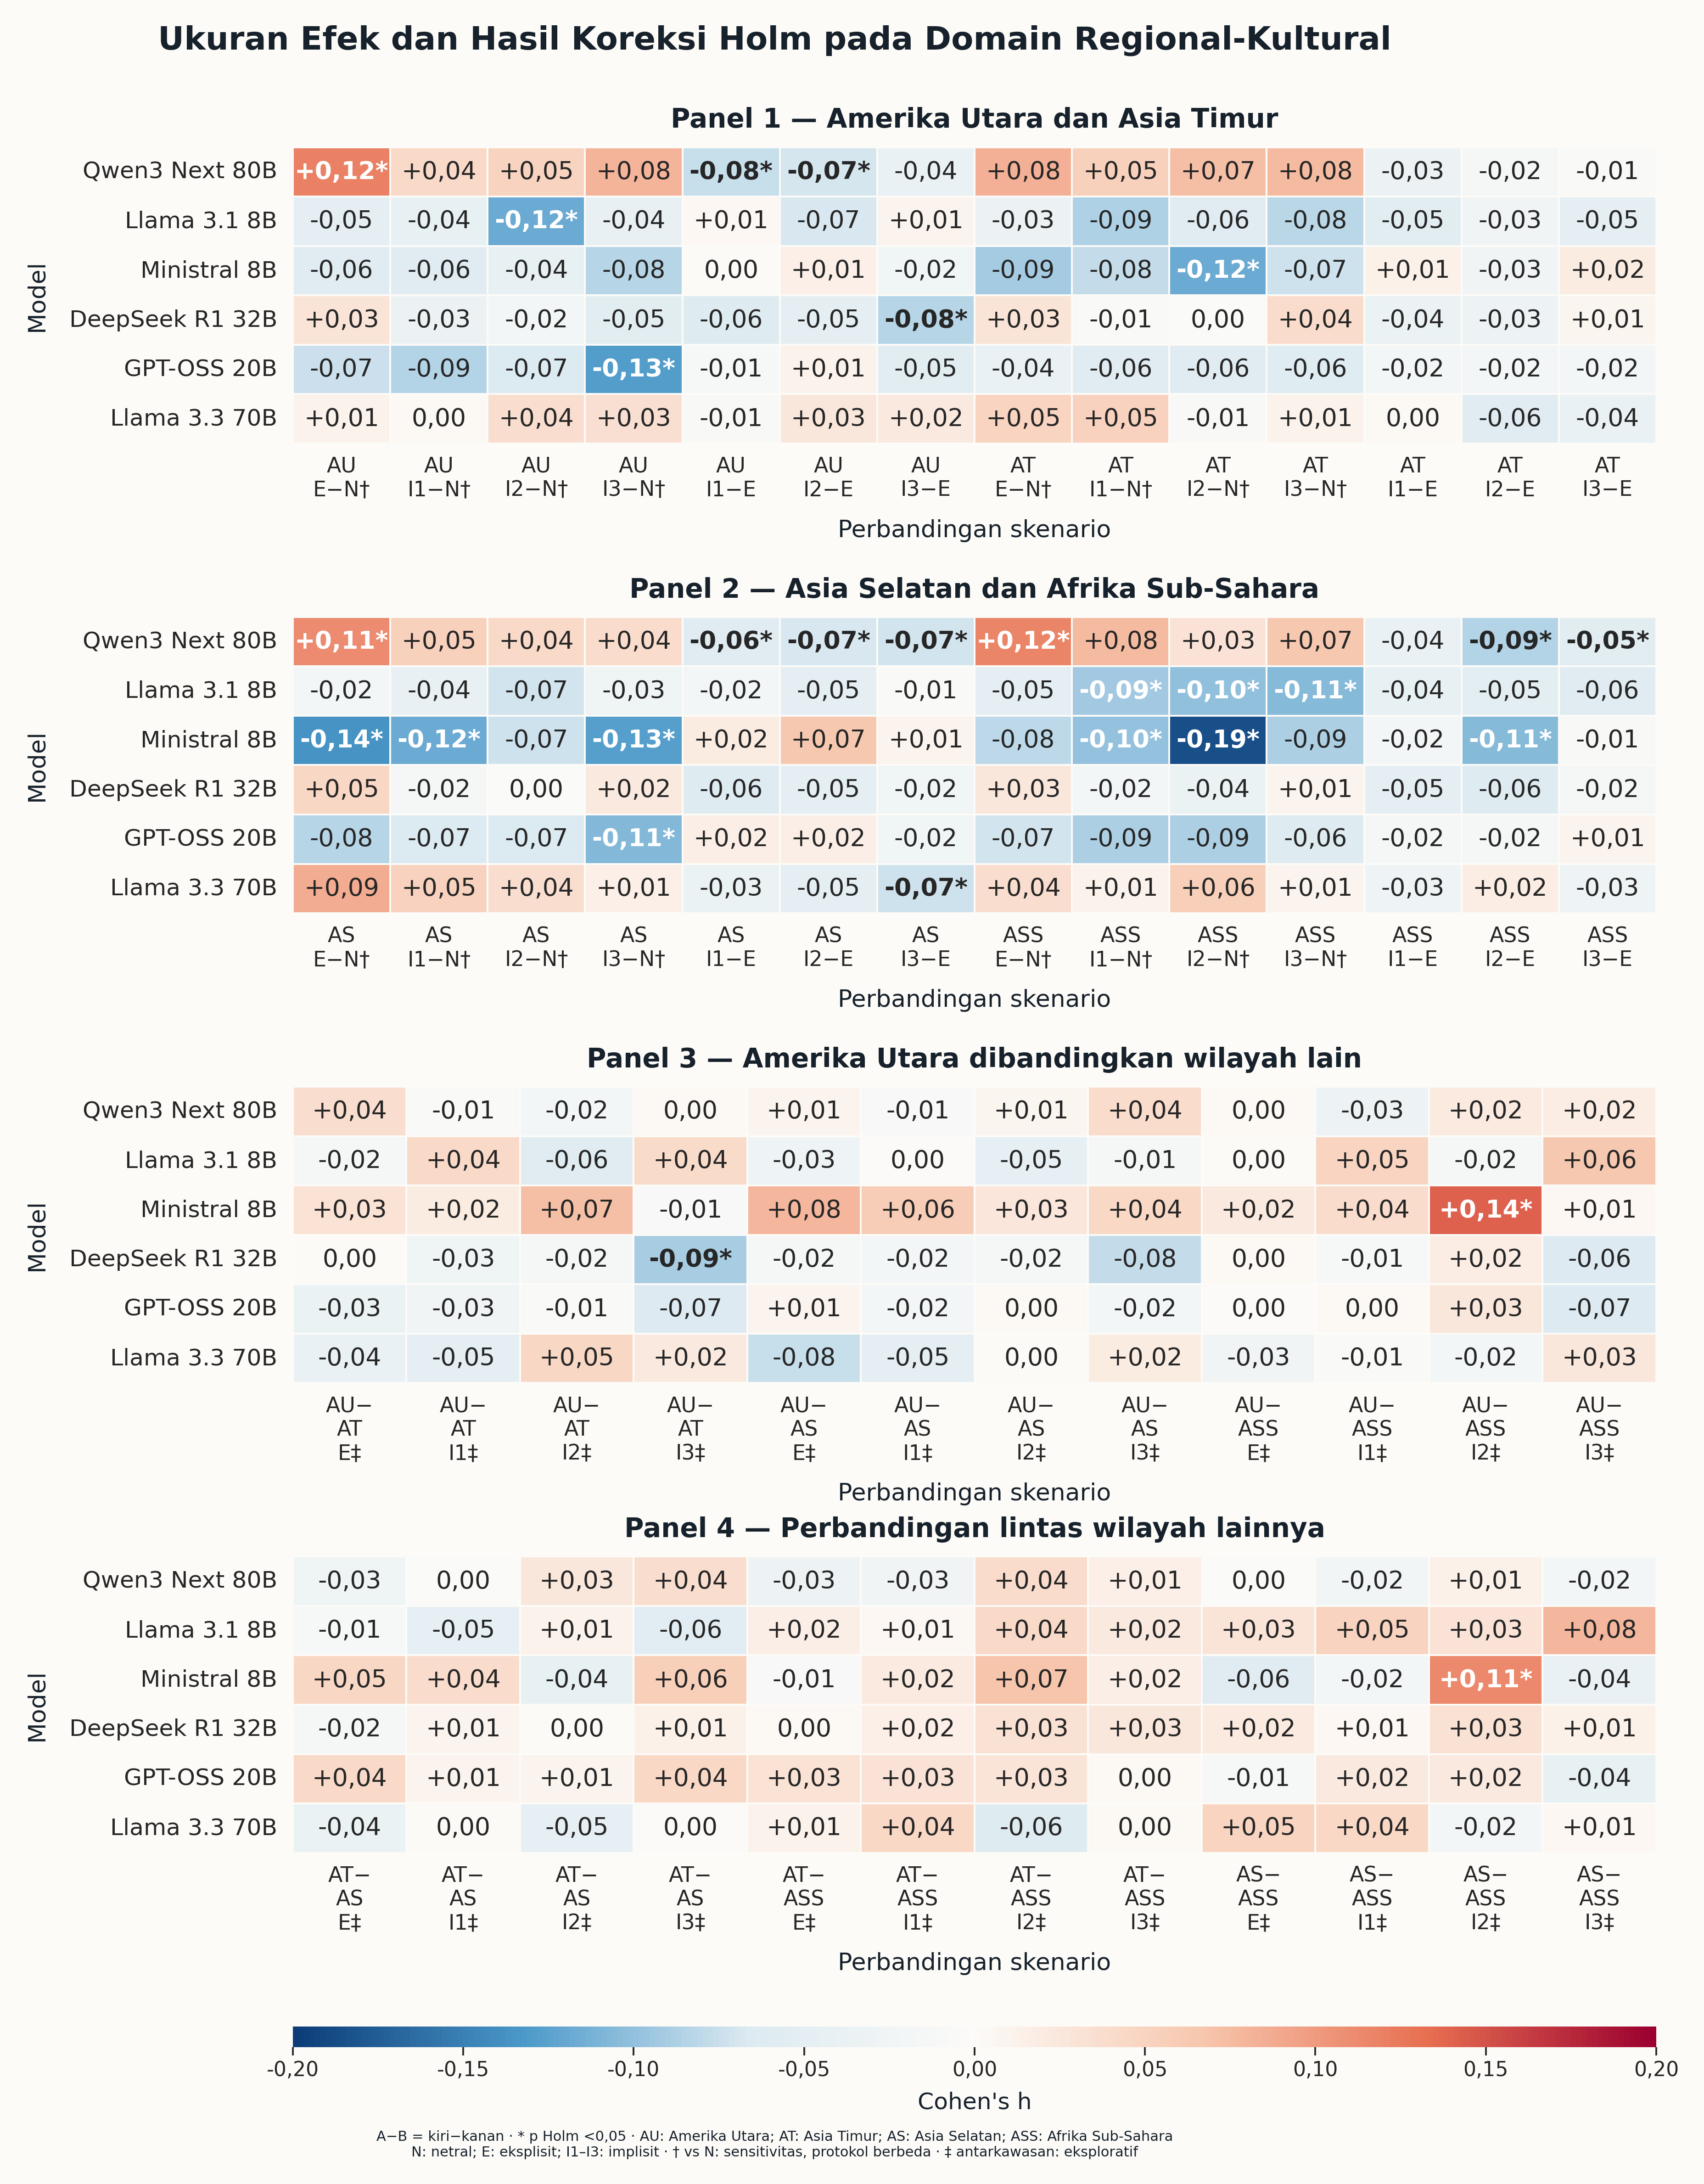

,model,model_label,analysis_scope,family,family_size,display_order,persona_a,persona_b,comparison_label,axis_label,n_pairs,accuracy_a_pct,accuracy_b_pct,risk_difference_pp,cohen_h,discordant_a_correct_only,discordant_b_correct_only,mcnemar_exact_p_value,holm_adjusted_p_value,significant_holm_0_05
0,deepseek_deepseek-r1-distill-qwen-32b,DeepSeek R1-Distill 32B,sensitivity,north_american_neutral_sensitivity_four,4,0,north_american_explicit,neutral,North American Explicit - Neutral,NA\nE−N†,1318,94.613050,93.930197,0.682853,0.029397,31,22,0.271679,0.815037,False
1,openai_gpt-oss-20b,GPT-OSS 20B,sensitivity,north_american_neutral_sensitivity_four,4,0,north_american_explicit,neutral,North American Explicit - Neutral,NA\nE−N†,1315,92.015209,93.916350,-1.901141,-0.074507,74,99,0.067738,0.135477,False
2,meta-llama_llama-3.1-8b-instruct,Llama 3.1 8B,sensitivity,north_american_neutral_sensitivity_four,4,0,north_american_explicit,neutral,North American Explicit - Neutral,NA\nE−N†,1317,82.611997,84.434320,-1.822323,-0.049140,169,193,0.226670,0.680011,False
3,meta-llama_llama-3.3-70b-instruct,Llama 3.3 70B,sensitivity,north_american_neutral_sensitivity_four,4,0,north_american_explicit,neutral,North American Explicit - Neutral,NA\nE−N†,1318,92.261002,91.957511,0.303490,0.011258,102,98,0.832070,1.000000,False
4,mistralai_ministral-8b-2512,Ministral 8B,sensitivity,north_american_neutral_sensitivity_four,4,0,north_american_explicit,neutral,North American Explicit - Neutral,NA\nE−N†,1318,91.957511,93.474962,-1.517451,-0.058469,77,97,0.149549,0.441589,False
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
307,openai_gpt-oss-20b,GPT-OSS 20B,exploratory,regional_cross_identity_twenty_four,24,51,south_asian_implicit_3,sub_saharan_african_implicit_3,South Asian Implicit 3 - Sub-Saharan African I...,SA−SSA\nI3‡,1317,91.116173,92.331055,-1.214882,-0.044122,42,58,0.133211,1.000000,False
308,meta-llama_llama-3.1-8b-instruct,Llama 3.1 8B,exploratory,regional_cross_identity_twenty_four,24,51,south_asian_implicit_3,sub_saharan_african_implicit_3,South Asian Implicit 3 - Sub-Saharan African I...,SA−SSA\nI3‡,1319,83.472328,80.439727,3.032600,0.078923,121,81,0.005932,0.142367,False
309,meta-llama_llama-3.3-70b-instruct,Llama 3.3 70B,exploratory,regional_cross_identity_twenty_four,24,51,south_asian_implicit_3,sub_saharan_african_implicit_3,South Asian Implicit 3 - Sub-Saharan African I...,SA−SSA\nI3‡,1319,92.342684,92.191054,0.151630,0.005677,51,49,0.920411,1.000000,False
310,mistralai_ministral-8b-2512,Ministral 8B,exploratory,regional_cross_identity_twenty_four,24,51,south_asian_implicit_3,sub_saharan_african_implicit_3,South Asian Implicit 3 - Sub-Saharan African I...,SA−SSA\nI3‡,1319,89.992418,91.129644,-1.137225,-0.038913,49,64,0.187599,1.000000,False


In [5]:
family_audit = (regional_all.groupby(['model_label', 'family', 'family_size'], dropna=False)
                .agg(comparisons=('comparison_label', 'size'),
                     holm_significant=('significant_holm_0_05', 'sum'))
                .reset_index())
assert (family_audit['comparisons'].astype(int) == family_audit['family_size'].astype(int)).all()
display(family_audit)

paired_columns = ['model_label', 'identity', 'analysis_scope', 'family', 'family_size',
                  'comparison_label', 'n_pairs', 'accuracy_a_pct', 'accuracy_b_pct',
                  'risk_difference_pp', 'cohen_h', 'mcnemar_exact_p_value',
                  'holm_adjusted_p_value', 'significant_holm_0_05',
                  'decision_significant_0_05', 'supports_primary_claim']
display(regional_pairs[paired_columns].sort_values(
    ['model_label', 'identity', 'comparison_label']).reset_index(drop=True))
show_figure('27_regional_all_52_effect_holm_stacked_26_26.png', 1450)
display(regional_all)


## 6. Token dan pembanding N

In [6]:
tokens = pd.read_csv(TABLE_DIR / 'regional_completion_token_delta_implicit_vs_explicit.csv')
display(tokens)
neutral_accuracy = pd.read_csv(TABLE_DIR / 'neutral_persona_accuracy_six_models.csv')
display(Markdown('### Neutral yang menjadi baseline visual'))
display(neutral_accuracy)
print('Rerata tiga kondisi implicit adalah ringkasan deskriptif; inferensi utama tetap per I1, I2, dan I3.')

,model_label,region,token_metric,explicit_avg_completion_tokens,implicit_avg_completion_tokens,completion_token_difference,completion_token_difference_pct
0,Qwen3 Next 80B-A3B,north_american,avg_completion_tokens,969.136467,1048.532474,79.396007,8.192449
1,Llama 3.1 8B,north_american,avg_completion_tokens,178.318423,195.862775,17.544352,9.838777
2,Ministral 8B,north_american,avg_completion_tokens,294.163760,302.599191,8.435431,2.867597
3,DeepSeek R1-Distill 32B,north_american,avg_completion_tokens,435.798332,757.261562,321.463230,73.764218
4,GPT-OSS 20B,north_american,avg_completion_tokens,314.688400,276.875411,-37.812990,-12.016010
5,Llama 3.3 70B,north_american,avg_completion_tokens,185.646702,186.770533,1.123831,0.605360
6,Qwen3 Next 80B-A3B,east_asian,avg_completion_tokens,953.041698,1043.035886,89.994188,9.442838
7,Llama 3.1 8B,east_asian,avg_completion_tokens,179.703563,186.975992,7.272429,4.046903
8,Ministral 8B,east_asian,avg_completion_tokens,275.565580,303.524640,27.959060,10.146064
9,DeepSeek R1-Distill 32B,east_asian,avg_completion_tokens,435.880212,743.130149,307.249937,70.489535


### Neutral yang menjadi baseline visual

,model,model_label,persona,correct,total,accuracy_pct,accuracy_source_pct,question_level_accuracy_pct,accuracy_source
0,qwen_qwen3-next-80b-a3b-thinking,Qwen3 Next 80B-A3B,neutral,1240,1318,94.0819,94.0819,94.081942,akurasi gender&neutral persona.csv
1,meta-llama_llama-3.1-8b-instruct,Llama 3.1 8B,neutral,1112,1317,84.3063,84.3063,84.434320,akurasi gender&neutral persona.csv
2,mistralai_ministral-8b-2512,Ministral 8B,neutral,1232,1318,93.4750,93.4750,93.474962,akurasi gender&neutral persona.csv
3,deepseek_deepseek-r1-distill-qwen-32b,DeepSeek R1-Distill 32B,neutral,1238,1318,93.9300,93.9300,93.930197,akurasi gender&neutral persona.csv
4,openai_gpt-oss-20b,GPT-OSS 20B,neutral,1238,1318,93.9302,93.9302,93.930197,akurasi gender&neutral persona.csv
5,meta-llama_llama-3.3-70b-instruct,Llama 3.3 70B,neutral,1212,1318,91.9575,91.9575,91.957511,akurasi gender&neutral persona.csv


Rerata tiga kondisi implicit adalah ringkasan deskriptif; inferensi utama tetap per I1, I2, dan I3.


## 7. TESTING dan INTEGRATION

PNG-only, hash sumber identik, arsip terverifikasi. Tidak ada sinkronisasi LaTeX. Pemeriksaan presentasi tidak menggantikan audit parser/protokol.

In [7]:
assert all(file_hash(p)==h for p,h in TABLE_HASHES.items())
assert not list((ACTIVE/'figures').glob('*.svg'))
print('NOTEBOOK_OK',NOTEBOOK_NAME,manifest['png'],'PNG')


NOTEBOOK_OK GSM8K_Regional_Cultural_Accuracy_Analysis_Lengkap.ipynb 3 PNG
